# CCE 3503 - Practical Machine Learning 
## Assignment 1: Feature Analysis
#### Name: Dave Galea
#### Student ID: 0283404L

***Additional library used:*** Feature-engine

The above library Feature-engine was used for random imputation using observed values, since scikit-learn's SimpleImputer does not provide this method. The library provides a ready-made imputer compatible with scikit-learn pipelines, avoiding the need to write a custom transformer. For consistency, even though this library was only needed for Random imputation, it was also used for median and mean imputations.

Feature-engine is open source under the BSD 3-Clause licence, free for commercial and non-commercial use, and has stable, maintained releases.
Documentation: https://feature-engine.trainindata.com/

In [2]:
%pip install feature-engine

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
import scipy as sp
import seaborn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from feature_engine.imputation import MeanMedianImputer, RandomSampleImputer
import matplotlib.pyplot as plt

## Task 1: Data cleaning, missing data, and normalization (+splitting)

Note: the above task has been modified to include the splitting from task 2 so to avoid data leakage.

In [4]:
raw_data = pd.read_csv("labelled.csv")
raw_data.head(10) # just getting an feel of the data

,id,new_tool_adoption_speed,code_review_effectiveness,attention_to_detail_score,empathy_rating_peer_avg,workload_capacity_rating,leadership_potential_rating,quantitative_analysis_score,communication_clarity_index,domain_knowledge_score,...,task_logging_completeness_rate,response_time_internal_comms_avg_hrs,task_decomposition_skill,perseverance_metric_avg_days,desk_location_zone_encoded,customer_support_rating_avg,internal_newsletter_open_rate,error_rate_reduction_percent,employee_discount_usage_rate,performance_score
0,8001,23,2.60,2.18,4.11,30.5,2.52,19.8,3.14,6.2,...,22.1,3.9,1.38,4.0,101,3.58,12.3,33.2,87.9,58.16
1,8002,11,3.97,3.52,4.26,66.1,3.41,64.3,4.29,21.2,...,62.7,2.1,2.34,7.0,102,4.38,10.4,66.5,31.6,84.12
2,8003,16,3.18,3.17,3.56,53.3,3.08,47.7,3.31,37.1,...,64.3,3.2,2.59,5.1,202,3.55,72.4,54.7,96.8,72.94
3,8004,16,3.03,3.65,3.05,59.9,3.39,41.2,2.89,68.7,...,75.1,2.0,3.38,5.8,201,3.65,53.9,64.5,48.5,51.76
4,8005,18,2.27,3.09,1.59,48.7,2.15,37.7,1.79,41.7,...,70.8,4.1,2.59,5.5,202,2.24,75.4,51.4,93.9,58.08
5,8006,8,4.36,2.93,5.00,74.4,4.03,78.2,4.66,45.2,...,70.6,1.9,3.20,5.3,201,4.53,83.9,73.4,65.1,64.86
6,8007,7,3.79,2.13,1.97,69.9,2.98,86.6,3.60,29.7,...,56.9,4.2,2.89,4.7,301,2.95,61.9,65.7,82.6,62.30
7,8008,26,2.19,1.00,3.60,9.3,2.66,15.5,3.03,18.3,...,0.0,6.4,1.72,1.0,102,2.80,60.1,7.8,55.7,57.49
8,8009,11,2.87,3.35,1.44,62.8,3.02,64.7,2.25,79.3,...,81.9,4.3,4.01,5.3,202,2.19,44.2,62.3,99.0,76.93
9,8010,19,2.93,2.97,4.49,45.6,3.04,32.5,3.21,35.0,...,58.7,2.9,2.34,5.4,101,3.75,58.6,48.9,23.4,60.87


### Subtask 1: Remove the non-predictive features and the potential target features from the dataset.

In [5]:
clean_data = raw_data.copy()

# Remove the non predictive features and target features
non_predictive = [
    "id", 
    "laptop_serial_number_last_digit", 
    "parking_bay_number",
    ]
target = [
    "performance_score",
    "manager_discretionary_bonus_count"
    ]

features_to_remove = non_predictive + target

clean_data = clean_data.drop(columns = features_to_remove)

clean_data.head(10)


,new_tool_adoption_speed,code_review_effectiveness,attention_to_detail_score,empathy_rating_peer_avg,workload_capacity_rating,leadership_potential_rating,quantitative_analysis_score,communication_clarity_index,domain_knowledge_score,first_pass_yield_rate,...,work_consistency_metric_std,task_logging_completeness_rate,response_time_internal_comms_avg_hrs,task_decomposition_skill,perseverance_metric_avg_days,desk_location_zone_encoded,customer_support_rating_avg,internal_newsletter_open_rate,error_rate_reduction_percent,employee_discount_usage_rate
0,23,2.60,2.18,4.11,30.5,2.52,19.8,3.14,6.2,35.9,...,6.99,22.1,3.9,1.38,4.0,101,3.58,12.3,33.2,87.9
1,11,3.97,3.52,4.26,66.1,3.41,64.3,4.29,21.2,66.9,...,3.66,62.7,2.1,2.34,7.0,102,4.38,10.4,66.5,31.6
2,16,3.18,3.17,3.56,53.3,3.08,47.7,3.31,37.1,56.0,...,5.85,64.3,3.2,2.59,5.1,202,3.55,72.4,54.7,96.8
3,16,3.03,3.65,3.05,59.9,3.39,41.2,2.89,68.7,69.1,...,5.29,75.1,2.0,3.38,5.8,201,3.65,53.9,64.5,48.5
4,18,2.27,3.09,1.59,48.7,2.15,37.7,1.79,41.7,54.1,...,5.38,70.8,4.1,2.59,5.5,202,2.24,75.4,51.4,93.9
5,8,4.36,2.93,5.00,74.4,4.03,78.2,4.66,45.2,72.4,...,5.71,70.6,1.9,3.20,5.3,201,4.53,83.9,73.4,65.1
6,7,3.79,2.13,1.97,69.9,2.98,86.6,3.60,29.7,61.4,...,6.24,56.9,4.2,2.89,4.7,301,2.95,61.9,65.7,82.6
7,26,2.19,1.00,3.60,9.3,2.66,15.5,3.03,18.3,6.4,...,10.00,0.0,6.4,1.72,1.0,102,2.80,60.1,7.8,55.7
8,11,2.87,3.35,1.44,62.8,3.02,64.7,2.25,79.3,61.8,...,5.62,81.9,4.3,4.01,5.3,202,2.19,44.2,62.3,99.0
9,19,2.93,2.97,4.49,45.6,3.04,32.5,3.21,35.0,52.1,...,5.56,58.7,2.9,2.34,5.4,101,3.75,58.6,48.9,23.4


#### A short comment on the above: 

##### Non predictive features
| Feature | Reason for removing |
| -------- | ------- |
| Id  |  The ID is unique for every single person, and has no effect on performance   |
| laptop_serial_number_last_digit | The last digit of a serial number is random for every person and has no effect on performance.     |
| parking_bay_number    |  Since we have no information of the parking layout (Some companies have it that certain areas are for different ranking employees), and the feature contains individual parking bay numbers rather than defined groups or zones, we can treat these numbers as effectively random identifiers with little expected effect on performance. This differs from desk_location_zone_encoded, which explicitly groups employees into zones; had the parking bay feature been recorded as, for example, "Area X" or "Level X", the feature would have been retained. |

Since the rules used to generate the synthetic dataset are unknown, my decision to remove features was not based on simply appearing unrelated to perfromance. Instead, they were removed based on the fact that they act as identifiers (id, serial numbers), or that they are simply arbitrary numbers (parking bay number); any apparent relationship with the performance score would simply be misleading in these cases. 

##### Potential Target Features
| Feature | Reason for removing |
| -------- | ------- |
| performance_score | Target Feature stated in the assignment description (not a potential target feature; just the target feature) |
| manager_discretionary_bonus_count | If bonuses are awarded based on the performance score, then we are using information that we not have access to at prediction time, thus causing data leakage. However, if bonuses are awarded before the final performance evaluation, the feature could be a valid predictor. Since the timing is unknown, I chose to exclude this feature so to err on the safer side. 

Other features, such as 360_feedback_score_avg, could also potentially introduce target leakage if they are dependent on an employee's performance_score. However, the rules used to generate the synthetic dataset are unknown, so this cannot be confirmed. I considered manager_discretionary_bonus_count a greater potential risk because, in my opinion,it is the feature most likely to be influenced by the final performance score. 

### Subtask 2: Randomly split the dataset into a train subset and test subset using an appropriate ratio of train subset samples to test subset samples. Comment on the choice of ratio.

In [6]:
X = clean_data # input features
y = raw_data["performance_score"] # target feature

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 4
)

Since we are going to be using wrapping methods, which typically use cross-validation, we use an 80/20 split which is the a common choice for when separate validation set is not used. This leaves 20% of the dataset (1000 rows in this case) left for testing the model at the end. 

### Subtask 3: Use appropriate techniques to handle features with missing data. Comment on why you selected the techniques used for missing data, and any adverse effect they may have on the data.

In [7]:
# First we see how much missing data we have in our dataset 
# how many employees have missing data?

# employees with at least one missing feature
employees_with_missing = (X_train == "?").any(axis=1).sum()

# employees with no missing features
employees_complete = (~(X_train == "?").any(axis=1)).sum()

print("Total employees:", len(X_train))
print("Employees with missing values:", employees_with_missing)
print("Employees with complete data:", employees_complete)


Total employees: 4000
Employees with missing values: 2910
Employees with complete data: 1090


From the above we know that elimination of all rows with a missing value is simply not an option. We can look into which features have the most missing values, and see if one feature is causing the discrepancy. 

In [8]:
# which features have missing data, and how much do they have missing?
missing_count = (X_train == "?").sum(axis=0)

missing_count = missing_count[missing_count > 0].sort_values(ascending=False)

print(missing_count.to_string())


favourite_music_genre           1697
commute_time_minutes             610
360_feedback_score_avg           604
client_satisfaction_score        389
technical_assessment_score       286
age                              208
on_time_task_completion_rate     198
sex                              163
team_collaboration_rating        156
avg_hours_worked_per_week        117


From the above, I have made the following decisions: 
- favourite_music_genre: remove the feature entirely. Although music taste could potentially have some indirect relationship with performance, with such high amount of missing data, imputing nearly half of the feature could significantly distort its original distribution. 
    - *Adverse effect*: removes any potential predictive power that the feature may have

- For the rest of the numerical features I will examine the distributions of each:
    - If the distribution is skewed, I will use the **median** for imputation as it is less affected by extreme values. 
        - *Adverse effect*: Can reduce variance and create an artificially concentrated area of values around the median

    - If the distribution is approximately symmetric, I will use the **mean**, as it represents the centre of data well. 
        - *Adverse effect*: Can reduce variance and create an artificially concentrated area of values around the mean.

    - If the distribution is approximately uniform, I will use **random** imputation using observed values, as this preserves the feature's overall distribution. Kurtosis will also be checked to support this. 
        - *Adverse effect*: Introduces randomness which may weaken relationships of the imputed feature with other features.

- For the categorical feature sex, I will see the ratio M and F currently have. If they are quite balanced, I will use **Random** imputation using observed values. Otherwise, I will use **Mode** imputation to fill in with the most dominant category.
    - *Adverse effect (Random)*: As stated above: Introduces randomness which may weaken relationships of the imputed feature with other features.
    - *Adverse effect (Mode)*: May exxagerate any existing imbalances present in the categorical data.

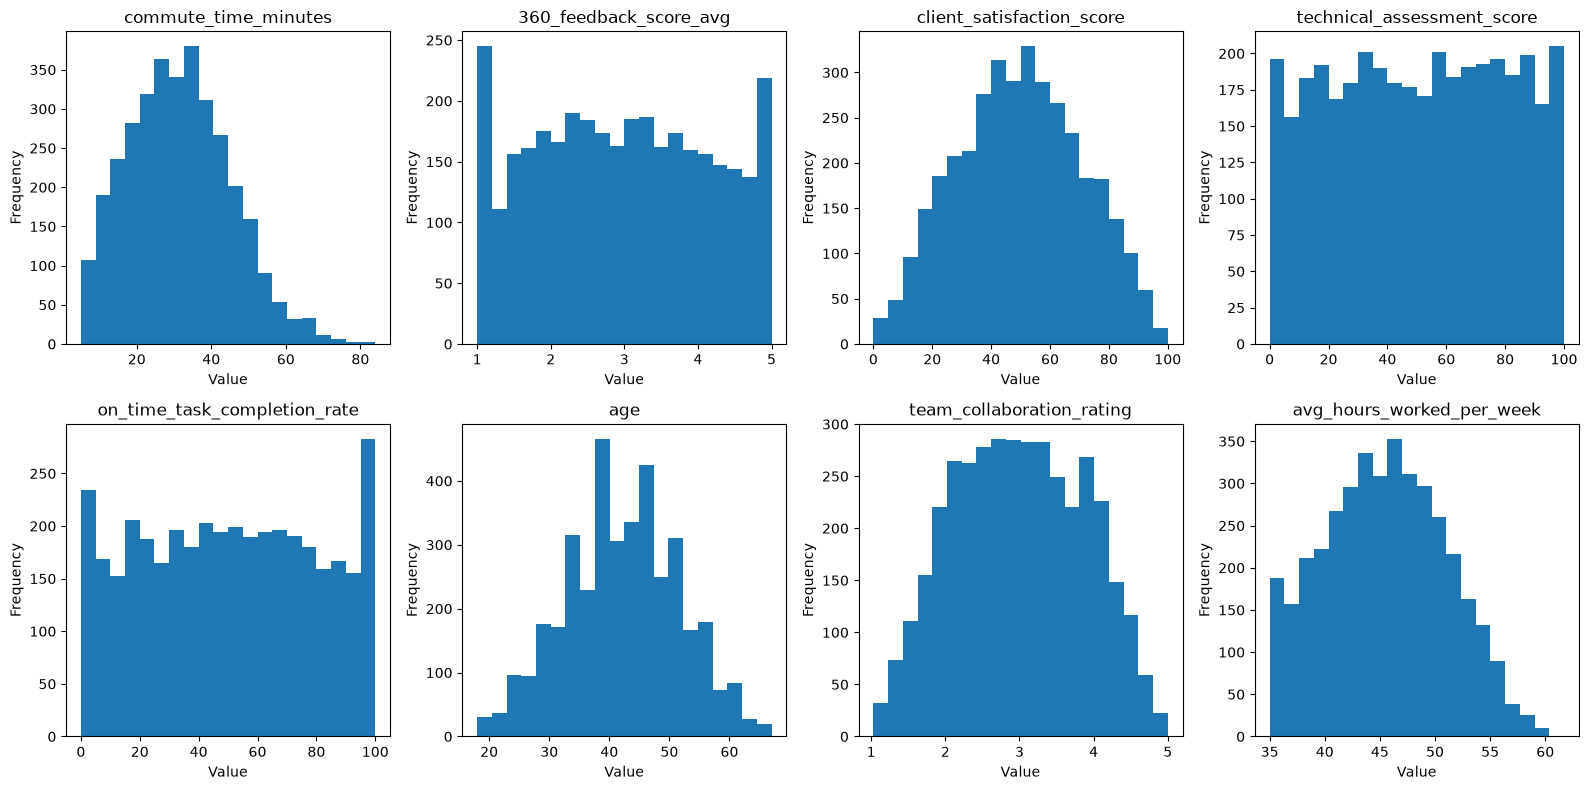

Skewness:
commute_time_minutes            0.361057
360_feedback_score_avg          0.032668
client_satisfaction_score       0.011022
technical_assessment_score     -0.025082
on_time_task_completion_rate    0.010178
age                            -0.032816
team_collaboration_rating       0.024096
avg_hours_worked_per_week       0.087215

Kurtosis:
commute_time_minutes           -0.174073
360_feedback_score_avg         -1.094221
client_satisfaction_score      -0.702135
technical_assessment_score     -1.177611
on_time_task_completion_rate   -1.129288
age                            -0.355886
team_collaboration_rating      -0.872346
avg_hours_worked_per_week      -0.670399


sex
M      1962
F      1875
NaN     163
Name: count, dtype: int64


In [9]:
# Drop the favourite_music_genre feature
X_train = X_train.drop(columns=["favourite_music_genre"])
X_test = X_test.drop(columns=["favourite_music_genre"])


# Convert missing-value markers to NaN
X_train = X_train.replace("?", np.nan)
X_test = X_test.replace("?", np.nan)

# Numerical features with missing values
numeric_features = [
    "commute_time_minutes",
    "360_feedback_score_avg",
    "client_satisfaction_score",
    "technical_assessment_score",
    "on_time_task_completion_rate",
    "age",
    "team_collaboration_rating",
    "avg_hours_worked_per_week"
]

numeric_data = X_train[numeric_features].apply(pd.to_numeric)
# Plot the distributions
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for feature, ax in zip(numeric_features, axes.flat):
    ax.hist(numeric_data[feature].dropna(), bins=20)
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# Calculate skewness and kurtosis for each numerical feature
skewness = numeric_data.skew()
kurtosis = numeric_data.kurt()

print("Skewness:")
print(skewness.to_string())

print("\nKurtosis:")
print(kurtosis.to_string())

# Categorical data handling 
print("\n")
print(X_train["sex"].value_counts(dropna=False))



From the above histograms, kurtosis values, skenwess values, and categorical distributions, the following decisions will apply:

To be imputed with **Mean** imputation (low skewness): 
- client_satisfaction_score
- age
- team_collaboration_rating
- avg_hours_worked_per_week (although seems visually skewed, numerically it is only very slightly skewed)

To be imputed with **Median** imputation (high skewness):
- commute_time_minutes

To be imputed with **Random** imputation (approximately uniform distribution):
- on_time_task_completion_rate
- 360_feedback_score_avg
- technical_assesment_score
- sex: the M and F categories are roughly equal in distribution.

In [10]:
mean_features = [
    "client_satisfaction_score",
    "age",
    "team_collaboration_rating",
    "avg_hours_worked_per_week"
]

median_features = [
    "commute_time_minutes"
]

random_features = [
    "on_time_task_completion_rate",
    "360_feedback_score_avg",
    "technical_assessment_score",
    "sex"
]

print(X_train[numeric_features].dtypes) # check types to see if we need to convert

# change to numerical types
X_train[numeric_features] = X_train[numeric_features].apply(pd.to_numeric)
X_test[numeric_features] = X_test[numeric_features].apply(pd.to_numeric)

'''
using a pipeline so that imputation is then done during validation 
rather than before so to prevent data leakage
'''
imputation_pipeline = Pipeline([
    ("mean", MeanMedianImputer(imputation_method = "mean", variables = mean_features)),
    ("median", MeanMedianImputer(imputation_method = "median", variables = median_features)),
    ("random", RandomSampleImputer(variables = random_features, random_state = 4))
])

commute_time_minutes            str
360_feedback_score_avg          str
client_satisfaction_score       str
technical_assessment_score      str
on_time_task_completion_rate    str
age                             str
team_collaboration_rating       str
avg_hours_worked_per_week       str
dtype: object


### Subtask 4: Normalize the data using an appropriate mechanism. Comment on the mechanism used and why you selected it.

Before normalizing the data, we must first one-hot encode the categorical features in the dataset: sex and department. Additionally, I will apply one-hot encoding to previously encoded categorical features that have no natural order, to avoid introducing false mathematical relationships between their values.

The choice to not re-encode company_merch_size_encoded is because clothing sizes do have a natural order, meaning its existing ordinal encoding may be appropriate given that 1 represents a smaller size than 4. 

In [11]:

categorical_features = [
    "sex",
    "department", 
    "favourite_colour_encoded", 
    "desk_location_zone_encoded"
]

# Encode categorical features
encoding = ColumnTransformer(
    transformers = [
        ("categorical", OneHotEncoder(
            categories = [
                ["F", "M"],
                ["Engineering", "Finance", "Operations", "Product", "Sales"],
                [1,2,3,4,5],
                [101, 102, 201, 202, 301] 
            ],
            drop = "if_binary", # create only one column for sex since its binary 
            handle_unknown = "ignore",
            sparse_output = False
        ), categorical_features)
    ],
    remainder = "passthrough", # dont change the other numerical columns
    verbose_feature_names_out = False # prevent the prefixes ColumnTransformer adds 
)

Regarding normalization, I have chosen to normalize using Min-Max scaling, which scales the training features to the range 0 to 1, preventing features with larger numerical ranges from dominating those with smaller ranges. The choice of scaling to the range 0 to 1 is particularly useful because it preserves the binary values produced by one-hot encoding.

In [12]:
# add to our current pipeline
preprocessing_pipeline = Pipeline([
    ("imputation", imputation_pipeline),
    ("encoding", encoding),
    ("normalization", MinMaxScaler()) # perform normalization 
])

## Task 2: Filter methods (-splitting)

### Subtask 1: Obtain a colour coded correlation matrix for the remaining features (for example using the pandas corr function and the seaborn heatmap function).

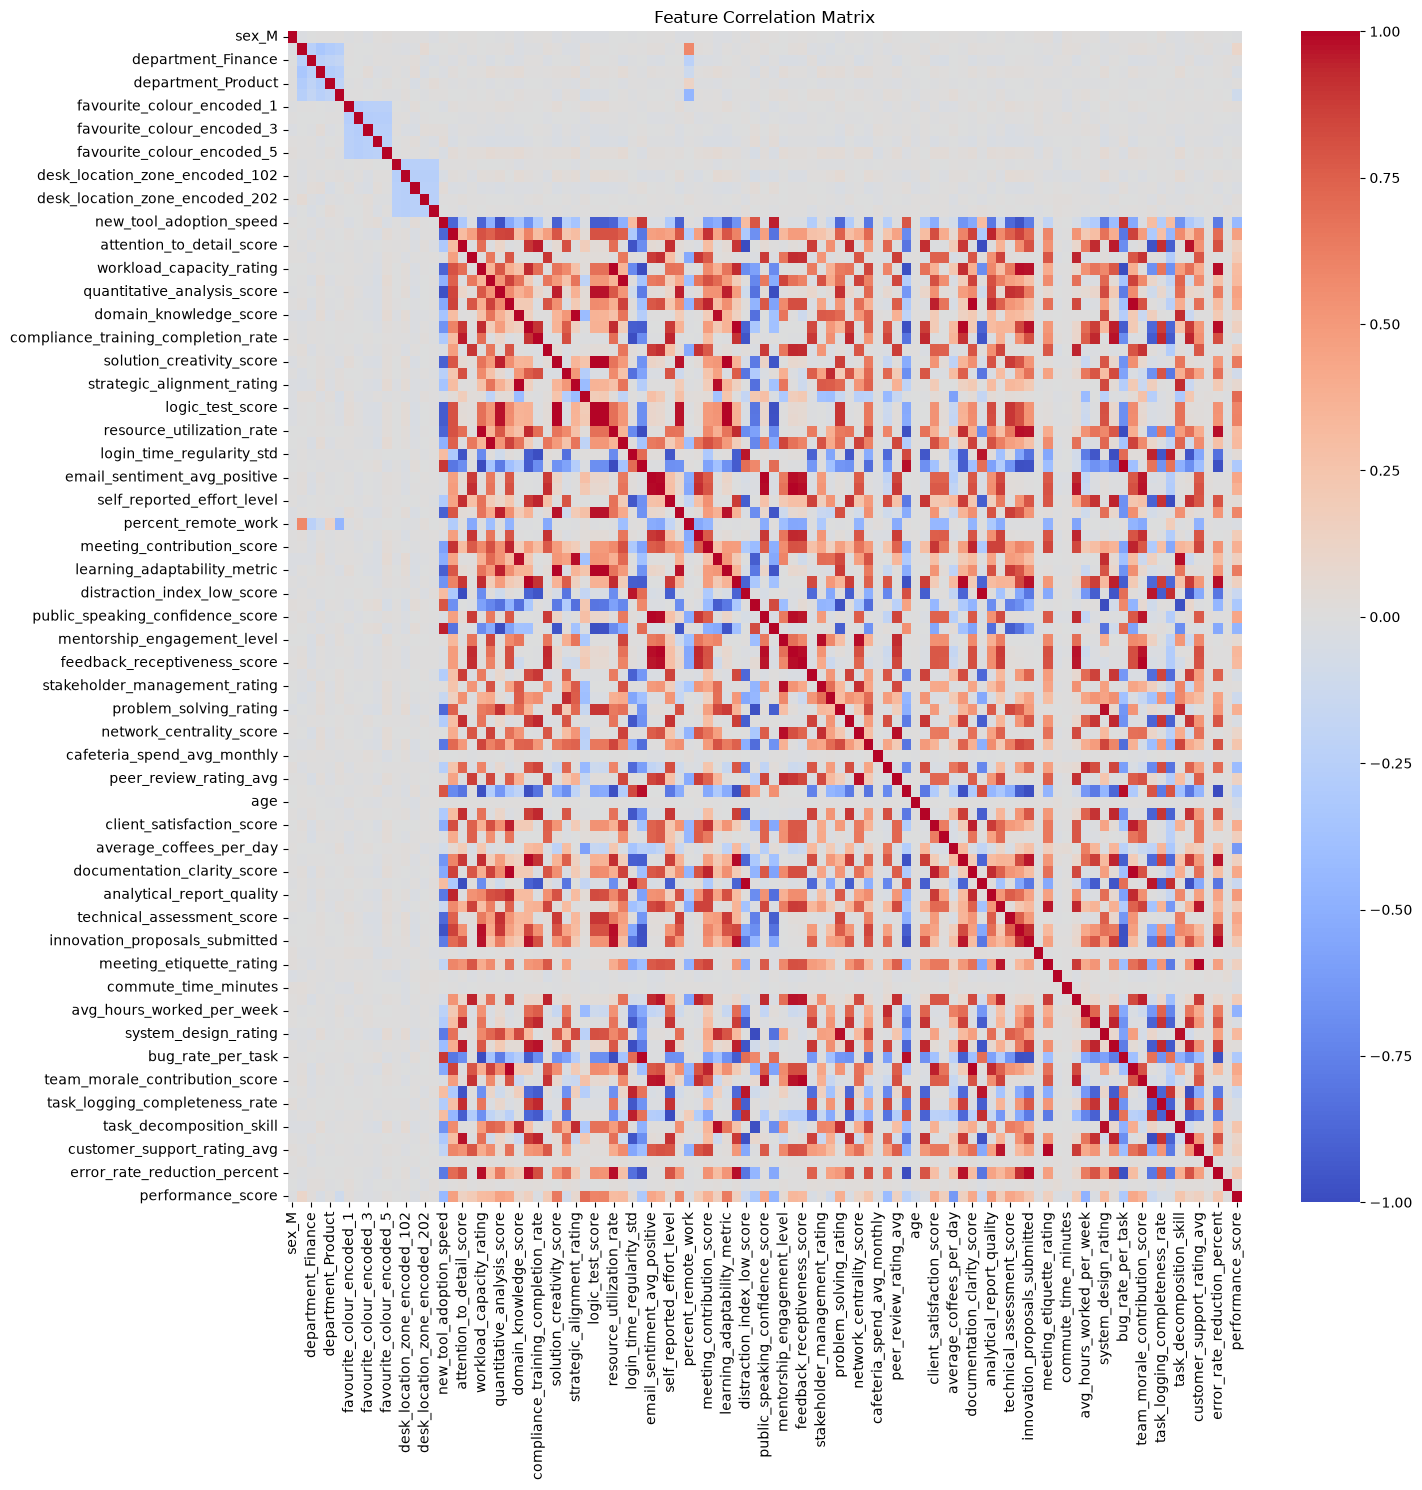

In [ ]:
X_train_processed = preprocessing_pipeline.fit_transform(X_train)
X_test_processed = preprocessing_pipeline.transform(X_test)
 # get all feature names from the encoding stage
feature_names = preprocessing_pipeline.named_steps["encoding"].get_feature_names_out() 

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns = feature_names,
    index = X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns = feature_names,
    index = X_test.index
)
# add back target feature 
correlation_data = X_train_processed.copy()
correlation_data["performance_score"] = y_train

# calculate Pearson correlation coefficients
correlations = correlation_data.corr()

# plot the correlation matrix
plt.figure(figsize=(15,15))

seaborn.heatmap(
    correlations,
    cmap = "coolwarm",
    vmin = -1,
    vmax = 1,
    center = 0
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

### Subtask 2: Select an appropriate threshold to apply to the correlation coefficient, and hence determine which features to keep. Comment on how you selected the threshold, referring to the heatmap if applicable.

churn_risk_score_inverted               0.709911
solution_creativity_score               0.642462
learning_adaptability_metric            0.636284
average_coffees_per_day                 0.628774
critical_thinking_index                 0.606247
logic_test_score                        0.594652
complex_task_efficiency                 0.587466
analytical_report_quality               0.494932
avg_hours_worked_per_week               0.476822
onboarding_ramp_time_days               0.465643
code_review_effectiveness               0.464359
quantitative_analysis_score             0.459721
technical_assessment_score              0.433338
public_speaking_confidence_score        0.432282
email_sentiment_avg_positive            0.432244
new_tool_adoption_speed                 0.431505
presentation_effectiveness_score        0.424200
documentation_clarity_score             0.424144
communication_clarity_index             0.424144
overtime_hours_voluntary_avg            0.420703
client_satisfaction_

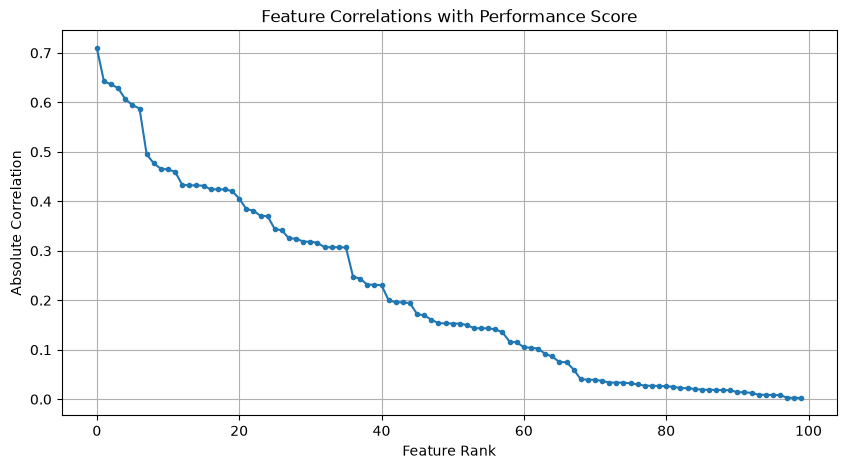

In [14]:
target_corrs = correlations["performance_score"].drop("performance_score") # exclude the correlation with itself
target_corrs = target_corrs.abs().sort_values(ascending=False)
print(target_corrs.to_string())

plt.figure(figsize=(10, 5))
plt.plot(target_corrs.values, marker=".")
plt.xlabel("Feature Rank")
plt.ylabel("Absolute Correlation")
plt.title("Feature Correlations with Performance Score")
plt.grid()
plt.show()

I chose an absolute correlation threshold of **0.30**, based on the observed correlations with performance_score. From the sorted correlation values, there is a noticeable drop from approximately 0.307 to 0.248, making 0.30 a reasonable cut-off point.

This threshold retains 36 features while removing 65 features with weaker relationships to the target. 

One limitation of this approach is that features with weak individual correlations may still provide useful information when combined with other features.

In [15]:
threshold = 0.30

selected_features = target_corrs[target_corrs > threshold].index
X_train_selected = X_train_processed[selected_features]

### Subtask 3: Train a neural network on the selected features to predict the employee performance score, and then use the trained network on the test subset to compute the root mean square error (RMSE).

In [ ]:
model_filter = MLPRegressor(
    hidden_layer_sizes = (100,50), # 100,50 example taken from lecture slides
    verbose = True,
    random_state = 4,
    max_iter = 500,
    early_stopping = True
)

model_filter.fit(X_train_selected, y_train)

Iteration 1, loss = 1694.91114853
Validation score: -11.933327
Iteration 2, loss = 1385.39697376
Validation score: -8.217684
Iteration 3, loss = 813.93269314
Validation score: -2.718305
Iteration 4, loss = 241.70160941
Validation score: 0.157792
Iteration 5, loss = 115.39926247
Validation score: 0.114469
Iteration 6, loss = 106.06585692
Validation score: 0.211592
Iteration 7, loss = 100.97414503
Validation score: 0.245510
Iteration 8, loss = 96.06753947
Validation score: 0.284973
Iteration 9, loss = 90.65604557
Validation score: 0.331573
Iteration 10, loss = 84.72215754
Validation score: 0.378352
Iteration 11, loss = 78.76107546
Validation score: 0.427962
Iteration 12, loss = 72.76491235
Validation score: 0.474402
Iteration 13, loss = 66.84818958
Validation score: 0.517520
Iteration 14, loss = 61.45925598
Validation score: 0.557653
Iteration 15, loss = 56.28944051
Validation score: 0.596798
Iteration 16, loss = 51.66177593
Validation score: 0.630213
Iteration 17, loss = 47.28543325
Val

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",4
,"verbose verbose: bool, default=FalseWhether to print progress messages to stdout.",True
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by atleast ``tol`` for ``n_iter_no_change`` consecutive epochs.Only effective when solver='sgd' or 'adam'.",True
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least to

In [ ]:
X_test_selected = X_test_processed[selected_features]

y_pred_filter = model_filter.predict(X_test_selected) # use the trained network on the test subset

# now calculatre RMSE 
filter_rmse = np.sqrt(mean_squared_error(y_test, y_pred_filter))
print("FILTER RMSE:", filter_rmse)

TASK 2 RMSE:  4.687933728873922


## Task 3: Wrapper Methods

### Subtask 1: Use Sequential Forward Selection (SFS) and Sequential Backward Selection (SBS) to obtain a maximum of 40 features in each case. Plot the RMSE against the number of features for both SFS and SBS, and use the shape of curves to justify your choise of the number of features.

In [23]:
# Prepare validation split
X_train_raw, X_validation_raw, y_train_subset, y_validation_subset = train_test_split(
    X_train, y_train, test_size = 0.2, random_state = 4
)

preprocessing = clone(preprocessing_pipeline) # fresh copy of task 1 preprocessing

X_train_subset = preprocessing.fit_transform(X_train_raw) # fit on training subset
X_validation_subset = preprocessing.transform(X_validation_raw) # transform validation subset

feature_names = list(preprocessing.named_steps["encoding"].get_feature_names_out())

model = MLPRegressor(
    hidden_layer_sizes = (100,50),
    max_iter = 1000,
    early_stopping = True,
    random_state = 4
)

In [ ]:
# the steps to implement SFS and SBS where taken directly from the notes
# SFS:
# Step 1: Start with an empty feature set 
selected_features = []
sfs_results = []

# Step 6: Repeat steps 2 to 5 until the stopping condition is reached (40 features selected)
while len(selected_features) < 40: 
    scores = {}

    # Step 4: Repeat steps 2 and 3 for all features not already in the set
    for feature in range(len(feature_names)): 
        if feature in selected_features: continue

        # step 2: Temporarily add a feature to the set and train the model 
        candidate_subset = selected_features + [feature]

        candidate_model = clone(model)
        candidate_model.fit(X_train_subset[:, candidate_subset], y_train_subset)

        # Step 3: Compute the evaluation metric and store it
        predictions = candidate_model.predict(X_validation_subset[:, candidate_subset])
        rmse = np.sqrt(mean_squared_error(y_validation_subset, predictions))

        scores[feature] = rmse

    # Step 5: Check which added feature gave the best evaluation metric and add it to the set permanently.
    best_feature = min(scores, key = scores.get)
    selected_features.append(best_feature)

    sfs_results.append((
        len(selected_features),
        scores[best_feature],
        selected_features.copy()
    ))

    print("SFS:", len(selected_features), "features, RMSE:", scores[best_feature])

/home/dave/miniconda3/envs/cps3235/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:792: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


In [ ]:
# SBS:
# Step 1: Start with a full feature set 
selected_features = list(range(len(feature_names)))
sbs_results = []

# Step 6: Repeat steps 2 to 5 until the stopping condition is reached (1 feature left)
while len(selected_features) > 1: 
    scores = {}

    # Step 4: Repeat steps 2 and 3 for all features already in the set
    for feature in selected_features: 

        # Step 2: Temporarily remove a feature from the set and train the model
        candidate_subset = [f for f in selected_features if f != feature]

        candidate_model = clone(model)
        candidate_model.fit(X_train_subset[:, candidate_subset], y_train_subset)

        # Step 3: Compute the evaluation metric and store it
        predictions = candidate_model.predict(X_validation_subset[:, candidate_subset])
        rmse = np.sqrt(mean_squared_error(y_validation_subset, predictions))

        scores[feature] = rmse

    # Step 5: Check which removed feature gave the best evaluation metric and remove it from the set permanently.
    best_feature = min(scores, key = scores.get)
    selected_features.remove(best_feature)

    if len(selected_features) <= 40:
        sbs_results.append((
            len(selected_features),
            scores[best_feature],
            selected_features.copy()
        ))

    print("SBS:", len(selected_features), "features, RMSE:", scores[best_feature])

In [ ]:
# Plot the RMSE against the number of features for both SFS and SBS
plt.figure(figsize=(10, 6))

plt.plot(
    [r[0] for r in sfs_results],
    [r[1] for r in sfs_results],
    label="SFS"
)

plt.plot(
    [r[0] for r in sbs_results],
    [r[1] for r in sbs_results],
    label="SBS"
)

plt.xlabel("Number of Features")
plt.ylabel("Validation RMSE")
plt.title("SFS vs SBS")
plt.legend()
plt.grid()
plt.show()

In [24]:
import time

def benchmark(n_features):
    times = []
    iterations = []

    # Test 10 candidate feature subsets
    for feature in range(n_features - 1, n_features + 9):
        candidate_subset = list(range(n_features - 1)) + [feature]

        test_model = clone(model)

        start = time.perf_counter()

        test_model.fit(X_train_subset[:, candidate_subset], y_train_subset)
        predictions = test_model.predict(X_validation_subset[:, candidate_subset])

        times.append(time.perf_counter() - start)
        iterations.append(test_model.n_iter_)

    print(
        f"{n_features} features:",
        f"Average iterations = {np.mean(iterations):.0f}",
        f"Average seconds per fit = {np.mean(times):.2f}"
    )

    return np.mean(times)


# Benchmark SFS and SBS
sfs_time = benchmark(20)
sbs_time = benchmark(67)

# Number of model fits with one validation split
sfs_fits = 3220
sbs_fits = 5049

sfs_hours = sfs_time * sfs_fits / 3600
sbs_hours = sbs_time * sbs_fits / 3600

print("\nEstimated runtime:")
print("SFS:", round(sfs_hours, 2), "hours")
print("SBS:", round(sbs_hours, 2), "hours")
print("Total:", round(sfs_hours + sbs_hours, 2), "hours")

20 features: Average iterations = 226 Average seconds per fit = 3.02
67 features: Average iterations = 120 Average seconds per fit = 2.09

Estimated runtime:
SFS: 2.7 hours
SBS: 2.92 hours
Total: 5.62 hours


## Task 4: Feature Projection

### Subtask 1: Use Principal Component Analysis (PCA) to reproject the features to principal components, and produce a plot to show the variance ratios of the principal components.

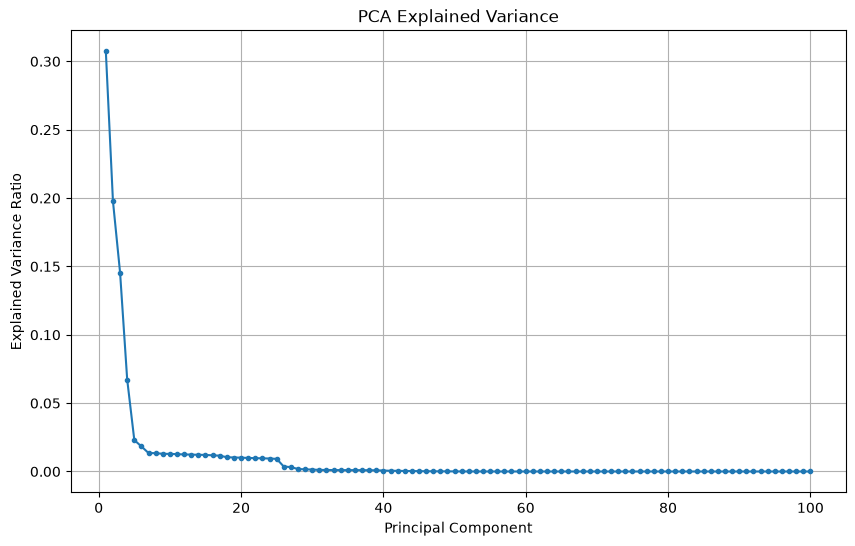

In [30]:
preprocessing_pca = clone(preprocessing_pipeline)
# replace the minmax scaling so to standardize before applying PCA
preprocessing_pca.set_params(normalization=StandardScaler())

X_train_pca_prepared = preprocessing_pca.fit_transform(X_train)
X_test_pca_prepared = preprocessing_pca.transform(X_test)

# Apply PCA 
pca = PCA()
pca.fit(X_train_pca_prepared)

# Get variance ratios
variance_ratios = pca.explained_variance_ratio_

# Plot explained variance
plt.figure(figsize = (10, 6))

plt.plot(
    range(1, len(variance_ratios) + 1),
    variance_ratios,
    marker = "."
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.grid()
plt.show()

### Subtask 2: Select an appropriate cut-off point and remove features beyond it. You can use a cumulative explained variance plot for this justification.

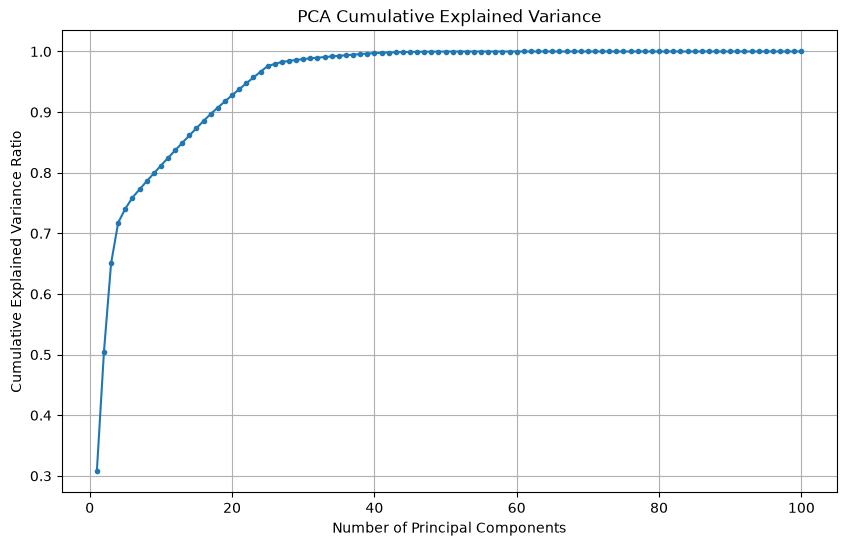

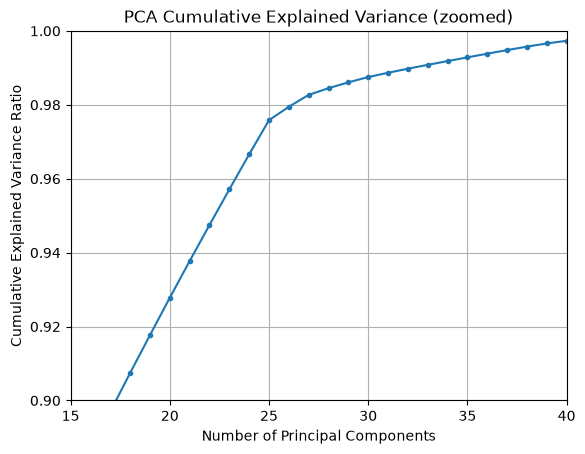

In [37]:
# Calculate cumulative explained variance
cumulative_variance = np.cumsum(variance_ratios)

# Plot cumulative explained variance
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="."
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("PCA Cumulative Explained Variance")
plt.grid()
plt.show()

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="."
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("PCA Cumulative Explained Variance (zoomed)")
plt.xlim(15, 40)
plt.ylim(0.90, 1.00)
plt.grid()
plt.show()

In [ ]:
# apply cutoff (25 components) 
pca_selected = PCA(n_components=25)

X_train_pca = pca_selected.fit_transform(X_train_pca_prepared)
X_test_pca = pca_selected.transform(X_test_pca_prepared)

print("Original features:", X_train_pca_prepared.shape[1])
print("Selected components:", X_train_pca.shape[1])
print("Variance retained:", pca_selected.explained_variance_ratio_.sum())

Original features: 100
Selected components: 25
Variance retained: 0.9758457331292758


### Subtask 3: Comment on how you picked the cut-off point.


I chose a cut off of **25 principal components** based on the cumulative explained variance plot. The curve rises relatively quickly up to approximately 25 components, after which the curve flattens, and one sees diminishing returns with regards to variance gain.

Therefore, I selected 25 components; this reduces the dimensionality from 100 to 25 while preserving **97.58%** of the original data's variance.

### Subtask 4: Discuss the strengths and limitations of PCA in this context

#### Strengths:



#### Limitations: 


### Subtask 5: Train a neural network using the same dataset split as Task 2 to predict the employee performance score, and compute the RMSE on the test subset.

In [40]:
model_pca = MLPRegressor(
    hidden_layer_sizes = (100,50),
    verbose = True,
    random_state = 4,
    max_iter = 500,
    early_stopping = True
)

model_pca.fit(X_train_pca, y_train)

Iteration 1, loss = 1644.54183928
Validation score: -8.782625
Iteration 2, loss = 1285.78843803
Validation score: -5.992295
Iteration 3, loss = 825.84912586
Validation score: -2.790218
Iteration 4, loss = 385.37852154
Validation score: -0.551455
Iteration 5, loss = 166.97605696
Validation score: 0.014087
Iteration 6, loss = 123.85409022
Validation score: 0.171463
Iteration 7, loss = 104.87969696
Validation score: 0.277100
Iteration 8, loss = 92.47061424
Validation score: 0.339595
Iteration 9, loss = 83.98760352
Validation score: 0.383602
Iteration 10, loss = 77.50144277
Validation score: 0.420850
Iteration 11, loss = 72.29176418
Validation score: 0.452376
Iteration 12, loss = 67.90477039
Validation score: 0.481666
Iteration 13, loss = 63.99230507
Validation score: 0.505768
Iteration 14, loss = 60.59087982
Validation score: 0.528646
Iteration 15, loss = 57.41025695
Validation score: 0.549401
Iteration 16, loss = 54.65591564
Validation score: 0.569510
Iteration 17, loss = 51.97923165
Val

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",4
,"verbose verbose: bool, default=FalseWhether to print progress messages to stdout.",True
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by atleast ``tol`` for ``n_iter_no_change`` consecutive epochs.Only effective when solver='sgd' or 'adam'.",True
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least to

In [41]:
# Predict using the test data
y_pred_pca = model_pca.predict(X_test_pca)

# Calculate test RMSE
pca_rmse = np.sqrt(mean_squared_error(y_test, y_pred_pca))

print("PCA RMSE:", pca_rmse)

PCA RMSE: 5.529983092196774


## Task 5: Comparison

## Task 6: Prediction on unlabelled samples